In [57]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [58]:
df=pd.read_csv('student_performance.csv')

In [59]:
df.drop(columns='Grade',inplace=True)

In [60]:
X = df.drop("Marks", axis=1)
y=df['Marks']

In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


In [62]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [63]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)), 
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1)
])

In [64]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [65]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 4333.2500 - mae: 64.4726 - val_loss: 5247.8496 - val_mae: 71.5280
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 4330.5923 - mae: 64.4531 - val_loss: 5244.9966 - val_mae: 71.5084
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 4327.8770 - mae: 64.4332 - val_loss: 5242.0557 - val_mae: 71.4881
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 4325.0850 - mae: 64.4127 - val_loss: 5239.0312 - val_mae: 71.4672
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 4322.1440 - mae: 64.3912 - val_loss: 5235.9253 - val_mae: 71.4458
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 4319.0537 - mae: 64.3687 - val_loss: 5232.7510 - val_mae: 71.4239
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 4315.8271 - mae: 64.3454 - val_loss: 5229.3306 - val_mae: 71.4004
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 4312.5386 - mae: 64.3216 - val_loss: 5225.4082 - val_mae: 71.3737
Epoch 9/

In [66]:
# Evaluate on the test set
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss (MSE): {test_loss:.4f}")
print(f"Test MAE: {test_mae:.4f}")

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate additional regression metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Absolute Error: {mae:.4f}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

# Compare a few actual vs predicted values
comparison = np.column_stack((y_test.values[:10], y_pred[:10].flatten()))
print("\nFirst 10 actual vs predicted:")
print(comparison)


Test Loss (MSE): 3438.8931
Test MAE: 57.6030
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step

Mean Absolute Error: 57.6030
Mean Squared Error: 3438.8929
Root Mean Squared Error: 58.6421
R² Score: -17.6709

First 10 actual vs predicted:
[[55.61        2.33565927]
 [78.79       16.54344749]
 [83.64       10.24189472]
 [69.96       19.61839485]
 [50.3         5.88768673]
 [73.49        3.48134804]
 [57.83        5.88659668]
 [80.89       18.49815559]
 [50.56        3.01786876]
 [53.64       13.56449127]]


In [67]:
print(df.head(10))
print("\nDataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
print(df[["Study_Hours", "Attendance", "Marks"]].describe())

print("\nMissing values:")
print(df[["Study_Hours", "Attendance", "Marks"]].isnull().sum())

   Study_Hours  Attendance  Marks
0         3.62       51.57  53.64
1         7.66       81.82  88.46
2         6.12       65.72  76.35
3         5.19       75.43  67.66
4         2.09       95.38  65.96
5         2.09       62.46  52.41
6         1.41       70.52  41.59
7         7.06       87.78  88.22
8         5.21       61.44  63.66
9         5.96       53.85  75.44

Dataset shape: (100, 3)

Data types:
Study_Hours    float64
Attendance     float64
Marks          float64
dtype: object

Summary statistics:
       Study_Hours  Attendance       Marks
count    100.00000  100.000000  100.000000
mean       4.29180   74.891500   66.266300
std        2.08272   14.655751   13.423856
min        1.04000   50.350000   41.450000
25%        2.35000   62.097500   55.985000
50%        4.25000   75.280000   65.555000
75%        6.11250   88.307500   77.092500
max        7.91000   99.280000   96.220000

Missing values:
Study_Hours    0
Attendance     0
Marks          0
dtype: int64


In [68]:
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[["Study_Hours", "Attendance"]]
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [84]:
print(X_test_scaled)

[[-1.39171392  1.29628107]
 [ 1.46283234 -0.05251799]
 [ 1.04593126  0.60171908]
 [ 0.66826792 -1.62588516]
 [-0.71976746 -0.76376616]
 [-0.09686819  1.6244425 ]
 [-0.60205422 -0.64835346]
 [ 1.35492853 -0.56839888]
 [-1.53885548 -0.74638473]
 [-0.32248525 -1.6446571 ]
 [-0.12629651  1.34912063]
 [ 0.47698389 -0.30281061]
 [ 1.19307282 -0.96678128]
 [ 1.64921165 -0.58021825]
 [-1.19552517 -1.42982261]
 [-1.07290721  1.40126492]
 [ 1.04102654  0.64830132]
 [-1.35247617 -0.40918496]
 [ 1.25192944  1.47774322]
 [-1.02386002 -0.98138168]]


In [69]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=8,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

In [70]:
y_pred = model.predict(X_test_scaled, verbose=0).flatten()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

print("\nActual vs Predicted:")
print(np.column_stack((
    y_test.to_numpy()[:10],
    y_pred[:10]
)))

MAE:  3.5847
MSE:  20.4896
RMSE: 4.5265
R²:   0.8888

Actual vs Predicted:
[[55.61       65.83309174]
 [78.79       84.62184906]
 [83.64       76.22094727]
 [69.96       70.90208435]
 [50.3        47.76665115]
 [73.49       74.08977509]
 [57.83       48.26464462]
 [80.89       82.32860565]
 [50.56       48.44968796]
 [53.64       55.75919724]]


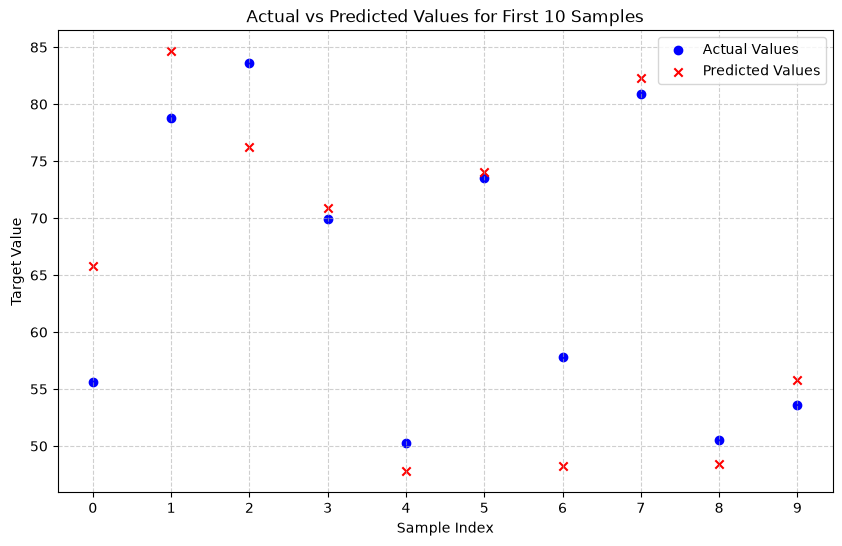

In [81]:
import numpy as np
import matplotlib.pyplot as plt

indices = np.arange(10)
plt.figure(figsize=(10, 6))
plt.scatter(indices, y_test[:10], color='blue', label='Actual Values')
plt.scatter(indices, y_pred[:10], color='red', label='Predicted Values', marker='x')

plt.xlabel('Sample Index')
plt.ylabel('Target Value')
plt.title('Actual vs Predicted Values for First 10 Samples')
plt.xticks(indices)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

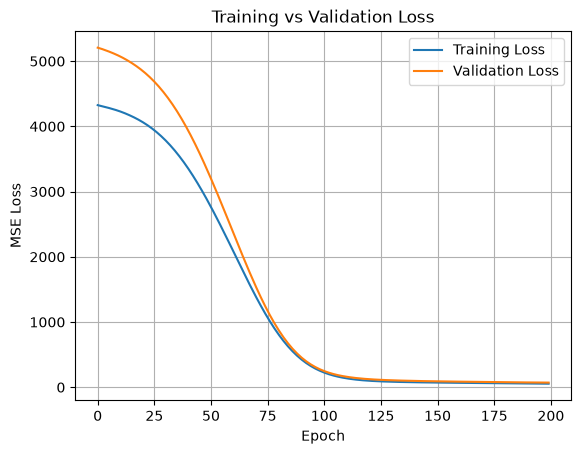

In [71]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [72]:
learning_rates = [0.01, 0.001, 0.0001]
results = []

for lr in learning_rates:
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(2,)),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(4, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="mse",
        metrics=["mae"]
    )

    history = model.fit(
        X_train_scaled,
        y_train,
        epochs=200,
        batch_size=8,
        validation_split=0.2,
        callbacks=[early_stop],
        verbose=0
    )

    best_val_loss = min(history.history["val_loss"])
    results.append((lr, best_val_loss))

for lr, loss in results:
    print(f"Learning rate: {lr}, "
          f"Best validation MSE: {loss:.4f}")

Learning rate: 0.01, Best validation MSE: 32.6917
Learning rate: 0.001, Best validation MSE: 84.9380
Learning rate: 0.0001, Best validation MSE: 4952.1860


In [73]:
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import mean_absolute_error, r2_score

# Reproducible random search
rng = np.random.default_rng(42)

results = []
best_val_loss = float("inf")
best_model = None
best_params = None

# Run 10 randomly selected trials
for trial in range(10):

    # Randomly select hyperparameters
    lr = 10 ** rng.uniform(-4, -2)
    batch_size = int(rng.choice([8, 16, 32]))
    neurons1 = int(rng.choice([4, 8, 16]))
    neurons2 = int(rng.choice([4, 8, 16]))

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(2,)),
        tf.keras.layers.Dense(neurons1, activation="relu"),
        tf.keras.layers.Dense(neurons2, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="mse",
        metrics=["mae"]
    )

    # Create a fresh callback for each trial
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_scaled,
        y_train,
        epochs=200,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=[early_stop],
        verbose=0
    )

    # Best validation loss for this trial
    trial_val_loss = min(history.history["val_loss"])

    results.append({
        "trial": trial + 1,
        "learning_rate": lr,
        "batch_size": batch_size,
        "neurons1": neurons1,
        "neurons2": neurons2,
        "val_mse": trial_val_loss
    })

    if trial_val_loss < best_val_loss:
        best_val_loss = trial_val_loss
        best_model = model
        best_params = results[-1].copy()

# Display all trials, best validation results first
results_df = pd.DataFrame(results).sort_values("val_mse")

print(results_df.to_string(index=False))
print("\nBest hyperparameters:")
print(best_params)

KeyboardInterrupt: 